In [ ]:
import csv
import pandas as pd
from pathlib import Path

PATHS = {
    "train": "/content/MahaSent_All_Train.csv",
    "validation": "/content/MahaSent_All_Val.csv",
    "test": "/content/MahaSent_All_Test.csv"
}

def load_csv_safely(path, split_name):
    rows = []

    with open(path, "r", encoding="utf-8", newline="") as f:
        reader = csv.DictReader(f, strict=True)

        if not {"text", "label"}.issubset(reader.fieldnames or []):
            raise ValueError(
                f"Unexpected columns in {split_name}: {reader.fieldnames}"
            )

        for record_num, row in enumerate(reader, start=1):
            try:
                label = int(row["label"].strip())
            except (ValueError, AttributeError):
                raise ValueError(
                    f"Invalid label in {split_name}, record {record_num}"
                )

            if label not in {-1, 0, 1}:
                raise ValueError(
                    f"Unexpected label {label} in {split_name}, "
                    f"record {record_num}"
                )

            rows.append({
                "text": row["text"],
                "label": label
            })

    df = pd.DataFrame(rows)
    df["text_normalized"] = (
        df["text"].fillna("").astype(str)
        .str.strip().str.split().str.join(" ")
    )

    print(f"{split_name}: {len(df):,} rows loaded")
    print("Label counts:", df["label"].value_counts().sort_index().to_dict())

    return df

train_df = load_csv_safely(PATHS["train"], "TRAIN")
val_df = load_csv_safely(PATHS["validation"], "VALIDATION")
test_df = load_csv_safely(PATHS["test"], "TEST")

TRAIN: 48,114 rows loaded
Label counts: {-1: 16038, 0: 16038, 1: 16038}
VALIDATION: 6,000 rows loaded
Label counts: {-1: 2000, 0: 2000, 1: 2000}
TEST: 6,750 rows loaded
Label counts: {-1: 2250, 0: 2250, 1: 2250}


In [ ]:
import pandas as pd

# Work on copies; preserve the original loaded DataFrames
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

def normalize_text(series):
    return (
        series.fillna("")
        .astype(str)
        .str.strip()
        .str.split()
        .str.join(" ")
    )

for df in [train_clean, val_clean, test_clean]:
    df["text_normalized"] = normalize_text(df["text"])

# Combine the splits to identify texts assigned multiple labels
combined = pd.concat(
    [
        train_clean[["text_normalized", "label"]],
        val_clean[["text_normalized", "label"]],
        test_clean[["text_normalized", "label"]]
    ],
    ignore_index=True
)

labels_per_text = combined.groupby("text_normalized")["label"].nunique()
conflict_texts = set(labels_per_text[labels_per_text > 1].index)

print("Unique texts with conflicting labels:", len(conflict_texts))

# Remove conflicting texts from every split
train_clean = train_clean[
    ~train_clean["text_normalized"].isin(conflict_texts)
].copy()

val_clean = val_clean[
    ~val_clean["text_normalized"].isin(conflict_texts)
].copy()

test_clean = test_clean[
    ~test_clean["text_normalized"].isin(conflict_texts)
].copy()

# Keep training examples; prevent the same normalized text
# from appearing in validation or test
train_texts = set(train_clean["text_normalized"])

val_clean = val_clean[
    ~val_clean["text_normalized"].isin(train_texts)
].copy()

val_texts = set(val_clean["text_normalized"])

test_clean = test_clean[
    ~test_clean["text_normalized"].isin(train_texts | val_texts)
].copy()

# Report the final working datasets
for name, df in [
    ("TRAIN", train_clean),
    ("VALIDATION", val_clean),
    ("TEST", test_clean)
]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Label counts:")
    print(df["label"].value_counts().sort_index().to_dict())
    print("Duplicate normalized texts:",
          int(df["text_normalized"].duplicated().sum()))

print("\nFinal cross-split overlap:")
print("Train-validation:",
      len(set(train_clean["text_normalized"]) &
          set(val_clean["text_normalized"])))
print("Train-test:",
      len(set(train_clean["text_normalized"]) &
          set(test_clean["text_normalized"])))
print("Validation-test:",
      len(set(val_clean["text_normalized"]) &
          set(test_clean["text_normalized"])))

Unique texts with conflicting labels: 48

TRAIN
Rows: 48002
Label counts:
{-1: 16011, 0: 15995, 1: 15996}
Duplicate normalized texts: 254

VALIDATION
Rows: 5931
Label counts:
{-1: 1987, 0: 1991, 1: 1953}
Duplicate normalized texts: 3

TEST
Rows: 6675
Label counts:
{-1: 2229, 0: 2236, 1: 2210}
Duplicate normalized texts: 2

Final cross-split overlap:
Train-validation: 0
Train-test: 0
Validation-test: 0


In [ ]:
import numpy as np
import pandas as pd

SEED = 42
NUM_CLIENTS = 3

# Remove exact duplicate texts within the training split.
# Conflicting-label texts were already removed in the previous step.
train_federated = train_clean.drop_duplicates(
    subset="text_normalized"
).reset_index(drop=True)

print("Training records available for federated learning:",
      len(train_federated))

def create_iid_clients(df, num_clients=3, seed=42):
    shuffled = df.sample(frac=1, random_state=seed).reset_index(drop=True)
    return [
        shuffled.iloc[i::num_clients].reset_index(drop=True)
        for i in range(num_clients)
    ]

def create_noniid_clients(df, num_clients=3, seed=42):
    rng = np.random.default_rng(seed)
    shuffled = df.sample(frac=1, random_state=seed).reset_index(drop=True)

    # Assign each class using different proportions across clients.
    # This simulates class-skewed clients, not actual geographic regions.
    class_weights = {
        -1: [0.70, 0.20, 0.10],
         0: [0.20, 0.60, 0.20],
         1: [0.10, 0.20, 0.70]
    }

    client_parts = [[] for _ in range(num_clients)]

    for label, group in shuffled.groupby("label"):
        group = group.sample(frac=1, random_state=seed + int(label) + 2)
        weights = np.array(class_weights[int(label)], dtype=float)
        weights /= weights.sum()

        proportions = rng.multinomial(len(group), weights)
        start = 0

        for client_id, count in enumerate(proportions):
            part = group.iloc[start:start + count]
            client_parts[client_id].append(part)
            start += count

    clients = []
    for parts in client_parts:
        client_df = pd.concat(parts, ignore_index=True)
        clients.append(client_df.sample(
            frac=1, random_state=seed
        ).reset_index(drop=True))

    return clients

iid_clients = create_iid_clients(
    train_federated, NUM_CLIENTS, SEED
)

noniid_clients = create_noniid_clients(
    train_federated, NUM_CLIENTS, SEED
)

def report_clients(clients, scenario):
    print(f"\n{scenario}")
    for i, client in enumerate(clients, start=1):
        print(f"\nClient {i}: {len(client)} records")
        print(client["label"].value_counts().sort_index().to_dict())

report_clients(iid_clients, "IID clients")
report_clients(noniid_clients, "Non-IID clients")

Training records available for federated learning: 47748

IID clients

Client 1: 15916 records
{-1: 5411, 0: 5260, 1: 5245}

Client 2: 15916 records
{-1: 5305, 0: 5335, 1: 5276}

Client 3: 15916 records
{-1: 5252, 0: 5361, 1: 5303}

Non-IID clients

Client 1: 16040 records
{-1: 11283, 0: 3145, 1: 1612}

Client 2: 15977 records
{-1: 3143, 0: 9604, 1: 3230}

Client 3: 15731 records
{-1: 1542, 0: 3207, 1: 10982}


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU in Colab: Runtime → Change runtime type → T4 GPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install transformers accelerate scikit-learn

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "google/muril-base-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model:", MODEL_NAME)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: google/muril-base-cased
Device: cuda
GPU: Tesla T4


In [ ]:
sample_texts = train_clean["text"].dropna().astype(str).head(3).tolist()

encoded = tokenizer(
    sample_texts,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Input shape:", encoded["input_ids"].shape)
print("Decoded example:")
print(tokenizer.decode(encoded["input_ids"][0], skip_special_tokens=True))

Input shape: torch.Size([3, 32])
Decoded example:
होता होता राहीलेला निवडणूक मारो मर्ज़ीभई


In [ ]:
# Map sentiment labels to model class IDs
LABEL_MAP = {-1: 0, 0: 1, 1: 2}
ID_TO_LABEL = {0: "negative", 1: "neutral", 2: "positive"}

for df in [train_clean, val_clean, test_clean]:
    df["label_id"] = df["label"].map(LABEL_MAP)

    if df["label_id"].isna().any():
        raise ValueError("Unexpected or missing sentiment labels.")

    df["label_id"] = df["label_id"].astype(int)

print("Label mapping:", ID_TO_LABEL)
print("\nTraining labels:")
print(train_clean["label_id"].value_counts().sort_index())

Label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}

Training labels:
label_id
0    16011
1    15995
2    15996
Name: count, dtype: int64


In [ ]:
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 8

class SentimentDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].fillna("").astype(str).tolist()
        self.labels = df["label_id"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        item = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        result = {
            key: value.squeeze(0)
            for key, value in item.items()
        }
        result["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return result

# Small pilot only
pilot_train = train_clean.sample(
    n=min(96, len(train_clean)),
    random_state=42
).reset_index(drop=True)

pilot_dataset = SentimentDataset(pilot_train, tokenizer)
pilot_loader = DataLoader(
    pilot_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

batch = next(iter(pilot_loader))

print("Pilot records:", len(pilot_dataset))
print("Batch input shape:", batch["input_ids"].shape)
print("Batch labels:", batch["labels"].tolist())

Pilot records: 96
Batch input shape: torch.Size([8, 128])
Batch labels: [1, 0, 2, 1, 0, 1, 1, 2]


In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Keep the pilot small for the first run
PILOT_TRAIN_SIZE = 384
PILOT_VAL_SIZE = 192
BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 2e-5

pilot_train = train_clean.sample(
    n=PILOT_TRAIN_SIZE, random_state=42
).reset_index(drop=True)

pilot_val = val_clean.sample(
    n=PILOT_VAL_SIZE, random_state=42
).reset_index(drop=True)

train_dataset = SentimentDataset(pilot_train, tokenizer, MAX_LENGTH)
val_dataset = SentimentDataset(pilot_val, tokenizer, MAX_LENGTH)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# Fresh model for the baseline
baseline_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID_TO_LABEL,
    label2id={v: k for k, v in ID_TO_LABEL.items()}
).to(device)

optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

# Mixed precision can reduce memory use on the T4
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

baseline_model.train()
running_loss = 0.0

for step, batch in enumerate(tqdm(train_loader, desc="Pilot training")):
    batch = {k: v.to(device) for k, v in batch.items()}

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=use_amp
    ):
        outputs = baseline_model(**batch)
        loss = outputs.loss

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    running_loss += loss.item()

print("Average training loss:", round(running_loss / len(train_loader), 4))

# Evaluate on the pilot validation sample
baseline_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Pilot evaluation"):
        labels = batch["labels"].numpy()
        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = baseline_model(**inputs).logits

        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.tolist())

print("\nPilot validation accuracy:",
      round(accuracy_score(all_labels, all_preds), 4))
print("Pilot validation macro-F1:",
      round(f1_score(all_labels, all_preds, average="macro"), 4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Pilot training:   0%|          | 0/48 [00:00<?, ?it/s]

Average training loss: 1.0984


Pilot evaluation:   0%|          | 0/24 [00:00<?, ?it/s]


Pilot validation accuracy: 0.276
Pilot validation macro-F1: 0.1442


In [ ]:
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
import torch

# Larger pilot
TRAIN_SIZE = 2400
VAL_SIZE = 600
BATCH_SIZE = 8
EPOCHS = 3
LEARNING_RATE = 2e-5
MAX_LENGTH = 128

pilot_train = train_clean.sample(
    n=TRAIN_SIZE, random_state=42
).reset_index(drop=True)

pilot_val = val_clean.sample(
    n=VAL_SIZE, random_state=42
).reset_index(drop=True)

train_dataset = SentimentDataset(pilot_train, tokenizer, MAX_LENGTH)
val_dataset = SentimentDataset(pilot_val, tokenizer, MAX_LENGTH)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# Start fresh rather than continuing from the previous pilot
del baseline_model
torch.cuda.empty_cache()

baseline_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID_TO_LABEL,
    label2id={v: k for k, v in ID_TO_LABEL.items()}
).to(device)

optimizer = torch.optim.AdamW(
    baseline_model.parameters(), lr=LEARNING_RATE
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

for epoch in range(EPOCHS):
    baseline_model.train()
    total_loss = 0.0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = baseline_model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()

    baseline_model.eval()
    predictions, actuals = [], []

    with torch.no_grad():
        for batch in val_loader:
            labels = batch["labels"].tolist()
            inputs = {
                k: v.to(device)
                for k, v in batch.items()
                if k != "labels"
            }

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                logits = baseline_model(**inputs).logits

            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            actuals.extend(labels)

    print(f"\nEpoch {epoch+1}")
    print("Training loss:", round(total_loss / len(train_loader), 4))
    print("Validation accuracy:",
          round(accuracy_score(actuals, predictions), 4))
    print("Validation macro-F1:",
          round(f1_score(actuals, predictions, average="macro"), 4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Epoch 1/3:   0%|          | 0/300 [00:00<?, ?it/s]


Epoch 1
Training loss: 1.0161
Validation accuracy: 0.7383
Validation macro-F1: 0.728


Epoch 2/3:   0%|          | 0/300 [00:00<?, ?it/s]


Epoch 2
Training loss: 0.7491
Validation accuracy: 0.7283
Validation macro-F1: 0.7226


Epoch 3/3:   0%|          | 0/300 [00:00<?, ?it/s]


Epoch 3
Training loss: 0.5518
Validation accuracy: 0.725
Validation macro-F1: 0.7234


In [ ]:
import os
import json

SAVE_DIR = "/content/muril_sentiment_pilot"

os.makedirs(SAVE_DIR, exist_ok=True)

baseline_model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

with open(os.path.join(SAVE_DIR, "label_mapping.json"), "w") as f:
    json.dump(
        {
            "original_to_model": {"-1": 0, "0": 1, "1": 2},
            "model_to_sentiment": {
                "0": "negative",
                "1": "neutral",
                "2": "positive"
            }
        },
        f,
        indent=4
    )

print("Pilot model saved to:", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Pilot model saved to: /content/muril_sentiment_pilot


In [ ]:

import os
import gc
import torch
import numpy as np

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Configuration
MODEL_NAME = "google/muril-base-cased"
BATCH_SIZE = 8
EPOCHS = 2
LEARNING_RATE = 2e-5
MAX_LENGTH = 128

SAVE_DIR = "/content/muril_centralized_baseline"
os.makedirs(SAVE_DIR, exist_ok=True)

# Verify that cleaned data and label mappings are available
assert "train_clean" in globals() and "val_clean" in globals()
assert "tokenizer" in globals()
assert "SentimentDataset" in globals()

for df in [train_clean, val_clean]:
    if "label_id" not in df.columns:
        df["label_id"] = df["label"].map({-1: 0, 0: 1, 1: 2})
    df["label_id"] = df["label_id"].astype(int)

print("Training records:", len(train_clean))
print("Validation records:", len(val_clean))

# Create datasets and loaders
train_dataset = SentimentDataset(
    train_clean, tokenizer, max_length=MAX_LENGTH
)
val_dataset = SentimentDataset(
    val_clean, tokenizer, max_length=MAX_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Free memory used by the pilot model
if "baseline_model" in globals():
    del baseline_model

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# Initialize a fresh centralized baseline
baseline_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
).to(device)

optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_val_f1 = -1.0
history = []

for epoch in range(EPOCHS):
    baseline_model.train()
    total_loss = 0.0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for batch in progress:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = baseline_model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = total_loss / len(train_loader)

    # Validation
    baseline_model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = baseline_model(**batch)

            preds = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_accuracy = accuracy_score(all_labels, all_preds)
    val_macro_f1 = f1_score(
        all_labels, all_preds, average="macro", zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "training_loss": avg_train_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1
    })

    print(f"\nEpoch {epoch + 1}")
    print(f"Training loss: {avg_train_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation macro-F1: {val_macro_f1:.4f}")

    # Save the best checkpoint based on validation macro-F1
    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        baseline_model.save_pretrained(SAVE_DIR)
        tokenizer.save_pretrained(SAVE_DIR)
        print("Best checkpoint saved.")

print("\nCentralized training completed.")
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print("Model directory:", SAVE_DIR)

import pandas as pd
history_df = pd.DataFrame(history)
display(history_df)


Training records: 48002
Validation records: 5931


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Epoch 1/2:   0%|          | 0/6001 [00:00<?, ?it/s]

Validation:   0%|          | 0/742 [00:00<?, ?it/s]


Epoch 1
Training loss: 0.6033
Validation accuracy: 0.7897
Validation macro-F1: 0.7881


... (4 outputs left out)


Epoch 2
Training loss: 0.4190
Validation accuracy: 0.7994
Validation macro-F1: 0.7984


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint saved.

Centralized training completed.
Best validation macro-F1: 0.7984
Model directory: /content/muril_centralized_baseline


,epoch,training_loss,validation_accuracy,validation_macro_f1
0,1,0.603254,0.789749,0.788099
1,2,0.418963,0.799359,0.798393


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Test evaluation:   0%|          | 0/835 [00:00<?, ?it/s]

Test accuracy: 0.8015
Test macro-precision: 0.8019
Test macro-recall: 0.8017
Test macro-F1: 0.8002

Classification report:
              precision    recall  f1-score   support

    Negative       0.78      0.88      0.83      2229
     Neutral       0.77      0.70      0.73      2236
    Positive       0.85      0.83      0.84      2210

    accuracy                           0.80      6675
   macro avg       0.80      0.80      0.80      6675
weighted avg       0.80      0.80      0.80      6675



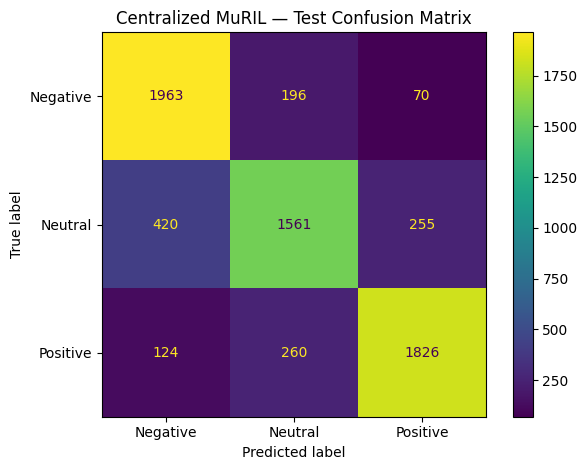

In [ ]:

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Ensure test labels use the correct mapping
if "label_id" not in test_clean.columns:
    test_clean["label_id"] = test_clean["label"].map(
        {-1: 0, 0: 1, 1: 2}
    )
test_clean["label_id"] = test_clean["label_id"].astype(int)

best_model = AutoModelForSequenceClassification.from_pretrained(
    SAVE_DIR
).to(device)
best_model.eval()

test_dataset = SentimentDataset(
    test_clean, tokenizer, max_length=MAX_LENGTH
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

y_true, y_pred = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test evaluation"):
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = best_model(**batch)

        predictions = torch.argmax(outputs.logits, dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))

precision, recall, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("Test macro-precision:", round(precision, 4))
print("Test macro-recall:", round(recall, 4))
print("Test macro-F1:", round(macro_f1, 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
display.plot(values_format="d")
plt.title("Centralized MuRIL — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import pandas as pd

# Create reproducible IID client partitions
SEED = 42
NUM_CLIENTS = 3

train_fed = train_clean.copy()

if "label_id" not in train_fed.columns:
    train_fed["label_id"] = train_fed["label"].map(
        {-1: 0, 0: 1, 1: 2}
    )

train_fed["label_id"] = train_fed["label_id"].astype(int)

# Shuffle and divide the training data into three nearly equal parts
shuffled_indices = train_fed.sample(
    frac=1, random_state=SEED
).index.to_numpy()

client_indices = np.array_split(shuffled_indices, NUM_CLIENTS)

iid_clients = [
    train_fed.loc[indices].reset_index(drop=True)
    for indices in client_indices
]

print("IID client preparation complete.")

for i, client_df in enumerate(iid_clients, start=1):
    print(f"\nClient {i}: {len(client_df)} records")
    print(client_df["label_id"].value_counts().sort_index().to_dict())

print("\nTotal client records:", sum(len(c) for c in iid_clients))

IID client preparation complete.

Client 1: 16001 records
{0: 5389, 1: 5372, 2: 5240}

Client 2: 16001 records
{0: 5338, 1: 5331, 2: 5332}

Client 3: 16000 records
{0: 5284, 1: 5292, 2: 5424}

Total client records: 48002


In [ ]:

import os
import gc
import copy
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

MODEL_NAME = "google/muril-base-cased"
FED_ROUNDS = 3
LOCAL_EPOCHS = 1
BATCH_SIZE = 8
MAX_LENGTH = 128
LEARNING_RATE = 2e-5

FED_SAVE_DIR = "/content/muril_fedavg_iid"
os.makedirs(FED_SAVE_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# Prepare validation labels
if "label_id" not in val_clean.columns:
    val_clean["label_id"] = val_clean["label"].map(
        {-1: 0, 0: 1, 1: 2}
    )
val_clean["label_id"] = val_clean["label_id"].astype(int)

val_dataset = SentimentDataset(
    val_clean, tokenizer, max_length=MAX_LENGTH
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_amp
)

# Initialize one global model and keep its weights on the CPU
global_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
)

global_state = {
    k: v.detach().cpu().clone()
    for k, v in global_model.state_dict().items()
}
del global_model
gc.collect()
if use_amp:
    torch.cuda.empty_cache()

def evaluate_global_state(state):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label={0: "negative", 1: "neutral", 2: "positive"},
        label2id={"negative": 0, "neutral": 1, "positive": 2}
    )
    model.load_state_dict(state)
    model.to(device)
    model.eval()

    y_true, y_pred = [], []

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(**batch)

            preds = outputs.logits.argmax(dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    del model
    gc.collect()
    if use_amp:
        torch.cuda.empty_cache()

    return accuracy, macro_f1

def train_one_client(client_df, starting_state, client_number, round_number):
    dataset = SentimentDataset(
        client_df, tokenizer, max_length=MAX_LENGTH
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=use_amp
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label={0: "negative", 1: "neutral", 2: "positive"},
        label2id={"negative": 0, "neutral": 1, "positive": 2}
    )
    model.load_state_dict(starting_state)
    model.to(device)
    model.train()

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    total_loss = 0.0
    steps = 0

    for local_epoch in range(LOCAL_EPOCHS):
        progress = tqdm(
            loader,
            desc=f"Round {round_number}, Client {client_number}",
            leave=False
        )

        for batch in progress:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(**batch)
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()
            steps += 1

    client_state = {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }

    avg_loss = total_loss / max(steps, 1)

    del model, optimizer, scaler, loader, dataset
    gc.collect()
    if use_amp:
        torch.cuda.empty_cache()

    return client_state, avg_loss

def fedavg_aggregate(client_states, client_sizes):
    total_size = sum(client_sizes)
    aggregated = {}

    for key in client_states[0]:
        first = client_states[0][key]

        # Weighted average for floating-point parameters/buffers
        if torch.is_floating_point(first):
            result = torch.zeros_like(first, dtype=torch.float32)

            for state, size in zip(client_states, client_sizes):
                result += state[key].float() * (size / total_size)

            aggregated[key] = result.to(first.dtype)
        else:
            # Keep integer buffers unchanged
            aggregated[key] = first.clone()

    return aggregated

best_val_f1 = -1.0
fed_history = []

for round_number in range(1, FED_ROUNDS + 1):
    print(f"\n========== FEDAVG ROUND {round_number}/{FED_ROUNDS} ==========")

    client_states = []
    client_sizes = []
    round_losses = []

    for client_number, client_df in enumerate(iid_clients, start=1):
        local_state, local_loss = train_one_client(
            client_df,
            global_state,
            client_number,
            round_number
        )

        client_states.append(local_state)
        client_sizes.append(len(client_df))
        round_losses.append(local_loss)

        print(
            f"Client {client_number}: "
            f"records={len(client_df)}, "
            f"local loss={local_loss:.4f}"
        )

    # Server aggregates the client model weights
    global_state = fedavg_aggregate(client_states, client_sizes)

    # Evaluate only on validation data during model selection
    val_accuracy, val_macro_f1 = evaluate_global_state(global_state)
    avg_client_loss = float(np.mean(round_losses))

    print(f"Average client training loss: {avg_client_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation macro-F1: {val_macro_f1:.4f}")

    fed_history.append({
        "round": round_number,
        "average_client_training_loss": avg_client_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1
    })

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1

        # Store the best global model weights
        best_state = {
            k: v.clone() for k, v in global_state.items()
        }

        save_model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3,
            id2label={0: "negative", 1: "neutral", 2: "positive"},
            label2id={"negative": 0, "neutral": 1, "positive": 2}
        )
        save_model.load_state_dict(best_state)
        save_model.save_pretrained(FED_SAVE_DIR)
        tokenizer.save_pretrained(FED_SAVE_DIR)
        del save_model

        print("Best global checkpoint saved.")

    del client_states
    gc.collect()
    if use_amp:
        torch.cuda.empty_cache()

fed_history_df = pd.DataFrame(fed_history)

print("\nIID FedAvg training completed.")
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Saved model:", FED_SAVE_DIR)

display(fed_history_df)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w


========== FEDAVG ROUND 1/3 ==========


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Round 1, Client 1:   0%|          | 0/2001 [00:00<?, ?it/s]

... (51 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best global checkpoint saved.

IID FedAvg training completed.
Best validation macro-F1: 0.8088
Saved model: /content/muril_fedavg_iid


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:

from IPython.display import display as show_table

show_table(fed_history_df)


,round,average_client_training_loss,validation_accuracy,validation_macro_f1
0,1,0.714154,0.796999,0.797150
1,2,0.517656,0.806104,0.805066
2,3,0.442062,0.810319,0.808761


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

IID FedAvg test evaluation:   0%|          | 0/835 [00:00<?, ?it/s]

IID FedAvg Test Accuracy: 0.8058
IID FedAvg Test Macro-Precision: 0.8047
IID FedAvg Test Macro-Recall: 0.8061
IID FedAvg Test Macro-F1: 0.804

Classification report:
              precision    recall  f1-score   support

    Negative       0.81      0.86      0.84      2229
     Neutral       0.78      0.69      0.74      2236
    Positive       0.82      0.86      0.84      2210

    accuracy                           0.81      6675
   macro avg       0.80      0.81      0.80      6675
weighted avg       0.80      0.81      0.80      6675



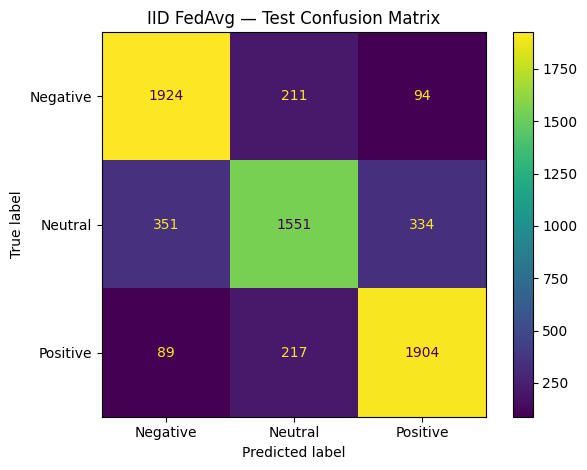

In [ ]:

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

if "label_id" not in test_clean.columns:
    test_clean["label_id"] = test_clean["label"].map(
        {-1: 0, 0: 1, 1: 2}
    )
test_clean["label_id"] = test_clean["label_id"].astype(int)

fed_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/muril_fedavg_iid"
).to(device)
fed_model.eval()

fed_test_dataset = SentimentDataset(
    test_clean, tokenizer, max_length=128
)
fed_test_loader = DataLoader(
    fed_test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

y_true_fed, y_pred_fed = [], []

with torch.no_grad():
    for batch in tqdm(fed_test_loader, desc="IID FedAvg test evaluation"):
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = fed_model(**batch)

        preds = outputs.logits.argmax(dim=1)
        y_true_fed.extend(labels.cpu().numpy())
        y_pred_fed.extend(preds.cpu().numpy())

fed_test_accuracy = accuracy_score(y_true_fed, y_pred_fed)

fed_precision, fed_recall, fed_macro_f1, _ = (
    precision_recall_fscore_support(
        y_true_fed, y_pred_fed,
        average="macro",
        zero_division=0
    )
)

print("IID FedAvg Test Accuracy:", round(fed_test_accuracy, 4))
print("IID FedAvg Test Macro-Precision:", round(fed_precision, 4))
print("IID FedAvg Test Macro-Recall:", round(fed_recall, 4))
print("IID FedAvg Test Macro-F1:", round(fed_macro_f1, 4))

print("\nClassification report:")
print(classification_report(
    y_true_fed, y_pred_fed,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

cm_fed = confusion_matrix(y_true_fed, y_pred_fed, labels=[0, 1, 2])
cm_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm_fed,
    display_labels=["Negative", "Neutral", "Positive"]
)
cm_plot.plot(values_format="d")
plt.title("IID FedAvg — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
import os
import time
import copy
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)
from tqdm.auto import tqdm

# -----------------------------
# 1. Configuration
# -----------------------------
MODEL_NAME = "google/muril-base-cased"
SAVE_PATH = "/content/muril_fedprox_iid"

NUM_CLIENTS = 3
FEDPROX_ROUNDS = 3
LOCAL_EPOCHS = 1
BATCH_SIZE = 8
LEARNING_RATE = 2e-5
MU = 0.01
MAX_LENGTH = 128
SEED = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
use_amp = device.type == "cuda"

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", device)
print("FedProx mu:", MU)

# -----------------------------
# 2. Create the same IID clients
# -----------------------------
train_fedprox = (
    train_clean.sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
    .copy()
)

client_dfs_fedprox = [
    part.reset_index(drop=True)
    for part in np.array_split(train_fedprox, NUM_CLIENTS)
]

print("\nIID FedProx clients:")
for i, client_df in enumerate(client_dfs_fedprox, start=1):
    print(f"Client {i}: {len(client_df)} records")

assert sum(len(df) for df in client_dfs_fedprox) == len(train_fedprox)

# Ensure label IDs are available
for df in [train_fedprox, val_clean]:
    if "label_id" not in df.columns:
        df["label_id"] = df["label"].map(
            {-1: 0, 0: 1, 1: 2}
        )
    df["label_id"] = df["label_id"].astype(int)

# -----------------------------
# 3. Validation function
# -----------------------------
def evaluate_fedprox(model, dataset):
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for batch in loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }
            labels = batch.pop("labels")

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(**batch)

            predictions = outputs.logits.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    return accuracy, precision, recall, macro_f1


val_dataset_fedprox = SentimentDataset(
    val_clean, tokenizer, max_length=MAX_LENGTH
)

# -----------------------------
# 4. Initialize global model
# -----------------------------
global_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

global_state = {
    key: value.detach().cpu().clone()
    for key, value in global_model.state_dict().items()
}

best_val_f1 = -1.0
history_fedprox = []

# -----------------------------
# 5. Federated training rounds
# -----------------------------
start_time = time.time()

for round_num in range(1, FEDPROX_ROUNDS + 1):
    print(f"\n{'=' * 45}")
    print(f"FedProx Round {round_num}/{FEDPROX_ROUNDS}")
    print(f"{'=' * 45}")

    client_states = []
    client_sizes = []
    client_losses = []

    for client_num, client_df in enumerate(
        client_dfs_fedprox, start=1
    ):
        print(f"\nTraining client {client_num}")

        # Start each client from the current global model
        local_model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3
        ).to(device)

        local_model.load_state_dict(global_state)

        # Save global parameters for the proximal term
        global_params = {
            name: parameter.detach().clone()
            for name, parameter in local_model.named_parameters()
        }

        local_dataset = SentimentDataset(
            client_df, tokenizer, max_length=MAX_LENGTH
        )

        local_loader = DataLoader(
            local_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0
        )

        optimizer = AdamW(
            local_model.parameters(),
            lr=LEARNING_RATE
        )

        local_model.train()
        total_loss = 0.0
        total_batches = 0

        for epoch in range(LOCAL_EPOCHS):
            for batch in tqdm(
                local_loader,
                desc=f"Client {client_num}, epoch {epoch + 1}",
                leave=False
            ):
                batch = {
                    key: value.to(device)
                    for key, value in batch.items()
                }

                optimizer.zero_grad(set_to_none=True)

                with torch.amp.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=use_amp
                ):
                    outputs = local_model(**batch)
                    task_loss = outputs.loss

                    # FedProx proximal regularization:
                    # (mu / 2) * ||local parameters - global parameters||^2
                    proximal_term = torch.zeros(
                        (), device=device
                    )

                    for name, parameter in local_model.named_parameters():
                        proximal_term = proximal_term + torch.sum(
                            (parameter - global_params[name]) ** 2
                        )

                    loss = task_loss + (MU / 2.0) * proximal_term

                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    local_model.parameters(), max_norm=1.0
                )
                optimizer.step()

                total_loss += task_loss.item()
                total_batches += 1

        avg_loss = total_loss / max(total_batches, 1)
        client_losses.append(avg_loss)

        client_states.append({
            key: value.detach().cpu().clone()
            for key, value in local_model.state_dict().items()
        })
        client_sizes.append(len(client_df))

        print(f"Client {client_num} task loss: {avg_loss:.4f}")

        del local_model, optimizer, local_loader, local_dataset
        if device.type == "cuda":
            torch.cuda.empty_cache()

    # -----------------------------
    # 6. Weighted server aggregation
    # -----------------------------
    total_records = sum(client_sizes)
    new_global_state = {}

    for key in global_state:
        # Average floating-point tensors by client dataset size.
        if torch.is_floating_point(global_state[key]):
            averaged = torch.zeros_like(global_state[key])

            for state, size in zip(client_states, client_sizes):
                averaged += state[key] * (size / total_records)

            new_global_state[key] = averaged
        else:
            # Preserve non-floating buffers safely.
            new_global_state[key] = global_state[key].clone()

    global_state = new_global_state
    global_model.load_state_dict(global_state)

    # -----------------------------
    # 7. Validation and checkpoint
    # -----------------------------
    val_acc, val_precision, val_recall, val_f1 = (
        evaluate_fedprox(global_model, val_dataset_fedprox)
    )

    avg_client_loss = float(np.mean(client_losses))

    history_fedprox.append({
        "Round": round_num,
        "Average_Client_Loss": avg_client_loss,
        "Validation_Accuracy": val_acc,
        "Validation_Macro_Precision": val_precision,
        "Validation_Macro_Recall": val_recall,
        "Validation_Macro_F1": val_f1
    })

    print(f"\nAverage client task loss: {avg_client_loss:.4f}")
    print(f"Validation accuracy:      {val_acc:.4f}")
    print(f"Validation macro-F1:      {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

        os.makedirs(SAVE_PATH, exist_ok=True)
        global_model.save_pretrained(SAVE_PATH)
        tokenizer.save_pretrained(SAVE_PATH)

        print("Best FedProx model saved.")

# -----------------------------
# 8. Results
# -----------------------------
fedprox_history_df = pd.DataFrame(history_fedprox)

print("\nFedProx training completed.")
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Total training time (minutes):",
      round((time.time() - start_time) / 60, 2))
print("Saved model:", SAVE_PATH)

from IPython.display import display as show_table
show_table(fedprox_history_df)

Device: cuda
FedProx mu: 0.01

IID FedProx clients:
Client 1: 16001 records
Client 2: 16001 records
Client 3: 16000 records


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w


FedProx Round 1/3

Training client 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (38 outputs left out)

Client 3 task loss: 0.5337

Average client task loss: 0.5314
Validation accuracy:      0.8076
Validation macro-F1:      0.8072


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best FedProx model saved.

FedProx training completed.
Best validation macro-F1: 0.8072
Total training time (minutes): 66.15
Saved model: /content/muril_fedprox_iid


,Round,Average_Client_Loss,Validation_Accuracy,Validation_Macro_Precision,Validation_Macro_Recall,Validation_Macro_F1
0,1,0.805547,0.775586,0.778250,0.776063,0.771034
1,2,0.600067,0.793627,0.793308,0.794134,0.792940
2,3,0.531388,0.807621,0.806750,0.807997,0.807163


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader
import torch
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

fedprox_test_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/muril_fedprox_iid"
).to(device)

fedprox_test_model.eval()

test_dataset = SentimentDataset(
    test_clean, tokenizer, max_length=128
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

y_true_prox, y_pred_prox = [], []
use_amp = device.type == "cuda"

with torch.no_grad():
    for batch in tqdm(test_loader, desc="FedProx test evaluation"):
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = fedprox_test_model(**batch)

        predictions = outputs.logits.argmax(dim=1)
        y_true_prox.extend(labels.cpu().numpy())
        y_pred_prox.extend(predictions.cpu().numpy())

prox_acc = accuracy_score(y_true_prox, y_pred_prox)

prox_precision, prox_recall, prox_f1, _ = (
    precision_recall_fscore_support(
        y_true_prox, y_pred_prox,
        average="macro", zero_division=0
    )
)

print("FedProx Test Accuracy:", round(prox_acc, 4))
print("FedProx Test Macro-Precision:", round(prox_precision, 4))
print("FedProx Test Macro-Recall:", round(prox_recall, 4))
print("FedProx Test Macro-F1:", round(prox_f1, 4))

print(classification_report(
    y_true_prox, y_pred_prox,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FedProx test evaluation:   0%|          | 0/835 [00:00<?, ?it/s]

FedProx Test Accuracy: 0.8028
FedProx Test Macro-Precision: 0.8018
FedProx Test Macro-Recall: 0.8031
FedProx Test Macro-F1: 0.802
              precision    recall  f1-score   support

    Negative       0.81      0.85      0.83      2229
     Neutral       0.76      0.71      0.74      2236
    Positive       0.83      0.84      0.84      2210

    accuracy                           0.80      6675
   macro avg       0.80      0.80      0.80      6675
weighted avg       0.80      0.80      0.80      6675



In [ ]:
import gc
import torch

# Release models and loaders left in memory
names_to_clear = [
    "local_model",
    "global_model",
    "fedprox_test_model",
    "fed_model",
    "optimizer",
    "local_loader",
    "test_loader",
    "fedprox_test_loader",
    "fed_test_loader",
    "local_dataset",
    "test_dataset",
    "test_dataset_fedprox",
    "fed_dataset",
    "outputs",
    "batch",
    "global_params",
    "client_states",
    "new_global_state",
]

for name in names_to_clear:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleanup attempted.")
print(torch.cuda.memory_summary(device=0, abbreviated=True))

GPU memory cleanup attempted.
|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 1            |        cudaMalloc retries: 2         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |  10012 MiB |  14400 MiB | 331083 GiB | 331073 GiB |
|---------------------------------------------------------------------------|
| Active memory         |  10012 MiB |  14400 MiB | 331083 GiB | 331073 GiB |
|---------------------------------------------------------------------------|
| Requested memory      |   9985 MiB |  14370 MiB | 319450 GiB | 319440 GiB |
|---------------------------------

In [ ]:
%pip install -q opacus

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.9/308.9 kB 10.5 MB/s eta 0:00:00


In [ ]:
from transformers import AutoModelForSequenceClassification
from opacus.validators import ModuleValidator

MODEL_PATH = "/content/muril_fedavg_iid"

# Load the saved FedAvg model
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH,
    num_labels=3
).to(device)

# IMPORTANT: validation is complaining that the model is not in training mode
base_model.train()

# Apply Opacus compatibility fixes
base_model = ModuleValidator.fix(base_model)
base_model = base_model.to(device)
base_model.train()

# Validate again and print the actual remaining issues
issues = ModuleValidator.validate(base_model, strict=False)

if issues:
    print("Remaining Opacus compatibility issues:")
    for issue in issues:
        print(f"- {issue}")
else:
    print("Model passed Opacus compatibility validation.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 19.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 14.03 GiB is allocated by PyTorch, and 384.35 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
!nvidia-smi

Sun Oct 18 17:12:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os

path = "/content/muril_fedavg_iid"
print("Checkpoint exists:", os.path.isdir(path))
if os.path.isdir(path):
    print(os.listdir(path)[:10])

Checkpoint exists: True
['tokenizer.json', 'model.safetensors', 'tokenizer_config.json', 'config.json']


In [ ]:
import torch
from transformers import AutoModelForSequenceClassification
from opacus.validators import ModuleValidator

MODEL_PATH = "/content/muril_fedavg_iid"

# Load the saved model on CPU only
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).cpu()

model.train()

# Apply Opacus compatibility fixes
model = ModuleValidator.fix(model)
model.train()

# Check for remaining issues
issues = ModuleValidator.validate(model, strict=False)

if issues:
    print("Remaining compatibility issues:")
    for issue in issues:
        print("-", issue)
else:
    print("Model passed Opacus compatibility validation.")

del model

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model passed Opacus compatibility validation.


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU allocated:", round(
        torch.cuda.memory_allocated() / 1024**3, 2
    ), "GiB")
    print("GPU reserved:", round(
        torch.cuda.memory_reserved() / 1024**3, 2
    ), "GiB")

import opacus
print("Opacus version:", opacus.__version__)

CUDA available: True
GPU allocated: 0.0 GiB
GPU reserved: 0.0 GiB
Opacus version: 1.6.0


In [ ]:

import csv
import gc
import pandas as pd
import torch

from torch.utils.data import Dataset
from transformers import AutoTokenizer

# Original files
TRAIN_PATH = "/content/MahaSent_All_Train.csv"
VAL_PATH   = "/content/MahaSent_All_Val.csv"
TEST_PATH  = "/content/MahaSent_All_Test.csv"

LABEL_MAP = {-1: 0, 0: 1, 1: 2}
MODEL_NAME = "google/muril-base-cased"

# Read CSV safely, preserving quoted multiline Marathi text
def load_original_csv(path):
    rows = []

    with open(path, "r", encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)

        if not {"text", "label"}.issubset(reader.fieldnames or []):
            raise ValueError(
                f"Expected text and label columns in {path}. "
                f"Found: {reader.fieldnames}"
            )

        for row in reader:
            text = str(row.get("text") or "").strip()

            if not text:
                continue

            try:
                label = int(row["label"])
            except (ValueError, TypeError):
                continue

            if label not in LABEL_MAP:
                continue

            rows.append({"text": text, "label": label})

    df = pd.DataFrame(rows)
    df["text_normalized"] = (
        df["text"].fillna("").astype(str)
        .str.strip().str.split().str.join(" ")
    )
    return df

train_raw = load_original_csv(TRAIN_PATH)
val_raw = load_original_csv(VAL_PATH)
test_raw = load_original_csv(TEST_PATH)

print("Loaded:", len(train_raw), len(val_raw), len(test_raw))

# Remove texts whose labels conflict across the original splits
all_data = pd.concat(
    [
        train_raw.assign(source="train"),
        val_raw.assign(source="val"),
        test_raw.assign(source="test")
    ],
    ignore_index=True
)

label_counts = all_data.groupby("text_normalized")["label"].nunique()
conflicting_texts = set(label_counts[label_counts > 1].index)

train_raw = train_raw[
    ~train_raw["text_normalized"].isin(conflicting_texts)
].copy()

val_raw = val_raw[
    ~val_raw["text_normalized"].isin(conflicting_texts)
].copy()

test_raw = test_raw[
    ~test_raw["text_normalized"].isin(conflicting_texts)
].copy()

# Keep training examples first to prevent cross-split text leakage
train_texts = set(train_raw["text_normalized"])

val_raw = val_raw[
    ~val_raw["text_normalized"].isin(train_texts)
].copy()

val_texts = set(val_raw["text_normalized"])

test_raw = test_raw[
    ~test_raw["text_normalized"].isin(train_texts | val_texts)
].copy()

# Recreate cleaned training set
train_clean = (
    train_raw.drop_duplicates(subset="text_normalized")
    .reset_index(drop=True)
)
val_clean = val_raw.reset_index(drop=True)
test_clean = test_raw.reset_index(drop=True)

# Restore label IDs
for df in [train_clean, val_clean, test_clean]:
    df["label_id"] = df["label"].map(LABEL_MAP).astype(int)

# Restore tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Restore dataset class
class SentimentDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.labels = df["label_id"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        item = {
            key: value.squeeze(0)
            for key, value in encoded.items()
        }
        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return item

print("\nCleaned training records:", len(train_clean))
print("Training label counts:")
print(train_clean["label"].value_counts().sort_index())
print("\nValidation records:", len(val_clean))
print("Test records:", len(test_clean))
print("Tokenizer and SentimentDataset restored.")
print("FedAvg checkpoint exists:",
      __import__("os").path.isdir("/content/muril_fedavg_iid"))


Loaded: 48112 5999 6750

Cleaned training records: 47747
Training label counts:
label
-1    15968
 0    15955
 1    15824
Name: count, dtype: int64

Validation records: 5931
Test records: 6675
Tokenizer and SentimentDataset restored.
FedAvg checkpoint exists: True


In [ ]:

import os
import gc
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader, Subset
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
from opacus.utils.batch_memory_manager import BatchMemoryManager

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
MODEL_NAME = "google/muril-base-cased"
OUTPUT_PATH = "/content/muril_fedavg_localdp_pilot"
ACCOUNTING_PATH = "/content/local_dp_privacy_accounting.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_CLIENTS = 3
RECORDS_PER_CLIENT = 200
MAX_LENGTH = 64
LOGICAL_BATCH_SIZE = 16
PHYSICAL_BATCH_SIZE = 1
LOCAL_EPOCHS = 1
TARGET_EPSILON = 8.0
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
LR = 1e-5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert "train_clean" in globals(), "Run the data restoration cell first."
assert "SentimentDataset" in globals(), "SentimentDataset is missing."
assert "tokenizer" in globals(), "Tokenizer is missing."
assert "label_id" in train_clean.columns, "label_id is missing."
assert len(train_clean) >= N_CLIENTS * RECORDS_PER_CLIENT

print("Device:", DEVICE)
print("Opacus:", __import__("opacus").__version__)

# --------------------------------------------------
# 2. Create three disjoint client subsets
# --------------------------------------------------
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(train_clean))

client_indices = [
    indices[i * RECORDS_PER_CLIENT:
            (i + 1) * RECORDS_PER_CLIENT].tolist()
    for i in range(N_CLIENTS)
]

client_datasets = [
    Subset(
        SentimentDataset(
            train_clean.iloc[idx].reset_index(drop=True),
            tokenizer,
            max_length=MAX_LENGTH
        ),
        list(range(len(idx)))
    )
    for idx in client_indices
]

print("Records per client:", [len(ds) for ds in client_datasets])

# --------------------------------------------------
# 3. Initialize from public pretrained MuRIL
#    NOT the non-private FedAvg checkpoint
# --------------------------------------------------
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).cpu()

base_model = ModuleValidator.fix(base_model)
base_model.train()

issues = ModuleValidator.validate(base_model, strict=False)
if issues:
    for issue in issues:
        print("Compatibility issue:", issue)
    raise RuntimeError(
        "Model failed Opacus validation. Stop without training."
    )

global_state = {
    key: value.detach().cpu().clone()
    for key, value in base_model.state_dict().items()
}

del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# --------------------------------------------------
# 4. Train each client with DP-SGD
# --------------------------------------------------
client_states = []
client_sizes = []
accounting_rows = []

for client_id, dataset in enumerate(client_datasets, start=1):
    print(f"\nPrivate training: client {client_id}")

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    ).cpu()

    model.load_state_dict(global_state)
    model = ModuleValidator.fix(model)
    model.train()

    model = model.to(DEVICE)

    loader = DataLoader(
        dataset,
        batch_size=LOGICAL_BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    privacy_engine = PrivacyEngine(accountant="rdp")

    model, optimizer, private_loader = (
        privacy_engine.make_private_with_epsilon(
            module=model,
            optimizer=optimizer,
            data_loader=loader,
            target_epsilon=TARGET_EPSILON,
            target_delta=DELTA,
            epochs=LOCAL_EPOCHS,
            max_grad_norm=MAX_GRAD_NORM,
            poisson_sampling=True
        )
    )

    total_loss = 0.0
    optimizer_steps = 0
    empty_batches = 0

    with BatchMemoryManager(
        data_loader=private_loader,
        max_physical_batch_size=PHYSICAL_BATCH_SIZE,
        optimizer=optimizer
    ) as memory_safe_loader:

        for batch in memory_safe_loader:
            # Do not silently skip an empty Poisson batch:
            # that would require careful handling of the mechanism
            # and accountant. Stop instead if one occurs.
            if batch["labels"].numel() == 0:
                empty_batches += 1
                raise RuntimeError(
                    f"Empty Poisson batch at client {client_id}. "
                    "Stop this run; do not claim a DP result."
                )

            optimizer.zero_grad(set_to_none=True)

            batch = {
                key: value.to(DEVICE)
                for key, value in batch.items()
            }

            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

            total_loss += float(loss.detach().cpu())
            optimizer_steps += 1

            del batch, outputs, loss

    epsilon = privacy_engine.get_epsilon(DELTA)

    print("Optimizer steps:", optimizer_steps)
    print("Mean loss:", round(
        total_loss / max(optimizer_steps, 1), 4
    ))
    print("Accountant epsilon:", round(epsilon, 4))
    print("Delta:", DELTA)

    accounting_rows.append({
        "client": client_id,
        "records": len(dataset),
        "target_epsilon": TARGET_EPSILON,
        "actual_epsilon": epsilon,
        "delta": DELTA,
        "optimizer_steps": optimizer_steps,
        "empty_batches": empty_batches,
        "noise_multiplier": float(optimizer.noise_multiplier),
        "max_grad_norm": MAX_GRAD_NORM
    })

    # Extract the underlying model's state on CPU
    underlying_model = model._module
    client_state = {
        key: value.detach().cpu().clone()
        for key, value in underlying_model.state_dict().items()
    }

    client_states.append(client_state)
    client_sizes.append(len(dataset))

    del underlying_model, model, optimizer
    del privacy_engine, private_loader, loader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------------------------------
# 5. Aggregate client models
# --------------------------------------------------
total_records = sum(client_sizes)

aggregated_state = {
    key: sum(
        client_states[i][key] * (client_sizes[i] / total_records)
        for i in range(N_CLIENTS)
    )
    for key in global_state
}

# --------------------------------------------------
# 6. Save model and accountant results
# --------------------------------------------------
final_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).cpu()

final_model.load_state_dict(aggregated_state)
final_model.save_pretrained(OUTPUT_PATH)
tokenizer.save_pretrained(OUTPUT_PATH)

privacy_df = pd.DataFrame(accounting_rows)
privacy_df.to_csv(ACCOUNTING_PATH, index=False)

print("\nPrivate pilot completed.")
print("Model:", OUTPUT_PATH)
print("Accountant results:", ACCOUNTING_PATH)
print(privacy_df.to_string(index=False))


Device: cuda
Opacus: 1.6.0
Records per client: [200, 200, 200]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w


Private training: client 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

... (7 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Private pilot completed.
Model: /content/muril_fedavg_localdp_pilot
Accountant results: /content/local_dp_privacy_accounting.csv
 client  records  target_epsilon  actual_epsilon   delta  optimizer_steps  empty_batches  noise_multiplier  max_grad_norm
      1      200             8.0        7.995135 0.00001              194              0          0.640564            1.0
      2      200             8.0        7.995135 0.00001              209              0          0.640564            1.0
      3      200             8.0        7.995135 0.00001              195              0          0.640564            1.0


In [ ]:

import gc
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

MODEL_PATH = "/content/muril_fedavg_localdp_pilot"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the same test split, with sequence length 64 for this pilot
test_dataset = SentimentDataset(
    test_clean.reset_index(drop=True),
    tokenizer,
    max_length=64
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(DEVICE)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        labels = batch.pop("labels").cpu().numpy()

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        logits = model(**batch).logits
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

        del batch, logits

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_preds)

print("DP pilot test results")
print("----------------------")
print(f"Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro-Precision:   {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro-Recall:      {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro-F1:          {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    zero_division=0
))

del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

DP pilot test results
----------------------
Accuracy:          0.3158
Macro-Precision:   0.1816
Macro-Recall:      0.3178
Macro-F1:          0.1798

Classification report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00      2229
     neutral       0.22      0.04      0.06      2236
    positive       0.32      0.92      0.48      2210

    accuracy                           0.32      6675
   macro avg       0.18      0.32      0.18      6675
weighted avg       0.18      0.32      0.18      6675



In [ ]:

import gc
import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

# Settings
MODEL_NAME = "google/muril-base-cased"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the same 600 records as the DP pilot
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(train_clean), size=600, replace=False
)
small_train = train_clean.iloc[sample_indices].reset_index(drop=True)

print("Training records:", len(small_train))
print("Device:", DEVICE)

# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_dataset = SentimentDataset(
    small_train, tokenizer, max_length=64
)
val_dataset = SentimentDataset(
    val_clean.reset_index(drop=True), tokenizer, max_length=64
)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=2e-5
)

# Train for one epoch
model.train()
total_loss = 0.0

for step, batch in enumerate(train_loader, start=1):
    batch = {
        key: value.to(DEVICE)
        for key, value in batch.items()
    }

    optimizer.zero_grad()
    outputs = model(**batch)
    loss = outputs.loss
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    if step % 20 == 0:
        print(f"Step {step}/{len(train_loader)}")

print("Average training loss:", round(
    total_loss / len(train_loader), 4
))

# Evaluate on validation data (not the test set)
model.eval()
predictions, actual = [], []

with torch.no_grad():
    for batch in val_loader:
        labels = batch.pop("labels").cpu().numpy()
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }
        logits = model(**batch).logits
        predictions.extend(logits.argmax(dim=1).cpu().numpy())
        actual.extend(labels)

print("\nNON-PRIVATE CONTROL RESULTS")
print("Validation accuracy:",
      round(accuracy_score(actual, predictions), 4))
print("Validation macro-F1:",
      round(f1_score(actual, predictions, average="macro",
                     zero_division=0), 4))

# Save the control model
model.save_pretrained("/content/muril_nonprivate_600_control")
tokenizer.save_pretrained("/content/muril_nonprivate_600_control")
print("Model saved successfully.")

del model, optimizer, train_loader, val_loader
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Training records: 600
Device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Step 20/75
Step 40/75
Step 60/75
Average training loss: 1.0973

NON-PRIVATE CONTROL RESULTS
Validation accuracy: 0.5217
Validation macro-F1: 0.4836


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully.


In [ ]:

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    "/content/muril_nonprivate_600_control"
).to(DEVICE)

val_dataset = SentimentDataset(
    val_clean.reset_index(drop=True),
    tokenizer,
    max_length=64
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

predictions = []
actual = []

model.eval()
with torch.no_grad():
    for batch in val_loader:
        labels = batch.pop("labels").cpu().numpy()
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }
        logits = model(**batch).logits
        predictions.extend(logits.argmax(dim=1).cpu().numpy())
        actual.extend(labels)

print("Prediction counts (negative=0, neutral=1, positive=2):")
print(np.bincount(predictions, minlength=3))

print("\nValidation classification report:")
print(classification_report(
    actual,
    predictions,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    zero_division=0
))

del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Prediction counts (negative=0, neutral=1, positive=2):
[4294  980  657]

Validation classification report:
              precision    recall  f1-score   support

    negative       0.45      0.98      0.62      1987
     neutral       0.55      0.27      0.36      1991
    positive       0.93      0.31      0.47      1953

    accuracy                           0.52      5931
   macro avg       0.64      0.52      0.48      5931
weighted avg       0.64      0.52      0.48      5931



In [ ]:

import gc
import torch
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/content/muril_nonprivate_600_control"

train_dataset = SentimentDataset(
    small_train.reset_index(drop=True),
    tokenizer,
    max_length=64
)
val_dataset = SentimentDataset(
    val_clean.reset_index(drop=True),
    tokenizer,
    max_length=64
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)

for epoch in range(1, 3):
    model.train()
    total_loss = 0

    for batch in train_loader:
        batch = {
            k: v.to(DEVICE) for k, v in batch.items()
        }
        optimizer.zero_grad()
        outputs = model(**batch)
        outputs.loss.backward()
        optimizer.step()
        total_loss += outputs.loss.item()

    model.eval()
    preds, actual = [], []

    with torch.no_grad():
        for batch in val_loader:
            labels = batch.pop("labels").cpu().tolist()
            batch = {
                k: v.to(DEVICE) for k, v in batch.items()
            }
            logits = model(**batch).logits
            preds.extend(logits.argmax(dim=1).cpu().tolist())
            actual.extend(labels)

    print(f"\nEpoch {epoch}")
    print(f"Training loss: {total_loss / len(train_loader):.4f}")
    print(f"Validation accuracy: {accuracy_score(actual, preds):.4f}")
    print(f"Validation macro-F1: {f1_score(actual, preds, average='macro', zero_division=0):.4f}")

model.save_pretrained(MODEL_PATH)
tokenizer.save_pretrained(MODEL_PATH)
print("\nUpdated control model saved.")

del model, optimizer, train_loader, val_loader
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Epoch 1
Training loss: 1.0703
Validation accuracy: 0.6190
Validation macro-F1: 0.5932

Epoch 2
Training loss: 1.0152
Validation accuracy: 0.6867
Validation macro-F1: 0.6766


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Updated control model saved.


In [ ]:
import os

print("Control model saved:",
      os.path.exists("/content/muril_nonprivate_600_control/config.json"))
print("DP pilot saved:",
      os.path.exists("/content/muril_fedavg_localdp_pilot/config.json"))
print("Training records available:", len(train_clean))
print("Validation records:", len(val_clean))

Control model saved: True
DP pilot saved: True
Training records available: 47747
Validation records: 5931


In [ ]:

import numpy as np

# Reproducible sample: 1,500 unique training records
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(train_clean),
    size=1500,
    replace=False
)

dp_train = train_clean.iloc[sample_indices].reset_index(drop=True)

# Split into 3 disjoint clients
client_data = [
    dp_train.iloc[i*500:(i+1)*500].reset_index(drop=True)
    for i in range(3)
]

print("Total records:", len(dp_train))

for i, client in enumerate(client_data, start=1):
    print(f"Client {i}: {len(client)} records")
    print("Class counts:", client["label_id"].value_counts().sort_index().to_dict())

print("\nPrivacy target: epsilon = 8.0, delta = 0.00001")
print("Local epochs planned: 2")
print("No model training performed yet.")


Total records: 1500
Client 1: 500 records
Class counts: {0: 179, 1: 154, 2: 167}
Client 2: 500 records
Class counts: {0: 161, 1: 178, 2: 161}
Client 3: 500 records
Class counts: {0: 158, 1: 173, 2: 169}

Privacy target: epsilon = 8.0, delta = 0.00001
Local epochs planned: 2
No model training performed yet.


In [ ]:

!pip -q install "opacus==1.6.0"

import gc
import os
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
from opacus.utils.batch_memory_manager import BatchMemoryManager

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------
MODEL_NAME = "google/muril-base-cased"
OUTPUT_PATH = "/content/muril_fedavg_localdp_1500"
ACCOUNTING_PATH = "/content/local_dp_privacy_accounting_1500.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAX_LENGTH = 64
BATCH_SIZE = 16
PHYSICAL_BATCH_SIZE = 1
LOCAL_EPOCHS = 2
TARGET_EPSILON = 8.0
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
LR = 1e-5

assert len(client_data) == 3, "Expected exactly 3 clients."
assert all(len(df) == 500 for df in client_data), (
    "Each client must contain 500 records."
)

print("Device:", DEVICE)
print("Clients:", len(client_data))
print("Records per client:", [len(df) for df in client_data])

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# --------------------------------------------------
# 2. CREATE AND VALIDATE MODEL
# --------------------------------------------------
def create_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    )
    model = ModuleValidator.fix(model)
    model.train()  # Important: Opacus requires training mode

    errors = ModuleValidator.validate(model, strict=False)
    if errors:
        raise RuntimeError(
            "Model is not Opacus-compatible after fix(): "
            + str(errors)
        )

    return model.to(DEVICE)

# Validate before starting the expensive client runs.
check_model = create_model()
print("Opacus model validation: passed")
del check_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# --------------------------------------------------
# 3. TRAIN EACH CLIENT WITH LOCAL DIFFERENTIAL PRIVACY
# --------------------------------------------------
client_states = []
privacy_rows = []

for client_id, client_df in enumerate(client_data, start=1):
    print(f"\n{'=' * 45}")
    print(f"Client {client_id}/3")
    print(f"{'=' * 45}")

    dataset = SentimentDataset(
        client_df.reset_index(drop=True),
        tokenizer,
        max_length=MAX_LENGTH
    )

    loader = torch.utils.data.DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    model = create_model()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR
    )

    # Experimental mode: secure RNG is disabled by default.
    # Do not claim production-grade privacy from this run.
    privacy_engine = PrivacyEngine(accountant="rdp")

    model, optimizer, private_loader = (
        privacy_engine.make_private_with_epsilon(
            module=model,
            optimizer=optimizer,
            data_loader=loader,
            target_epsilon=TARGET_EPSILON,
            target_delta=DELTA,
            epochs=LOCAL_EPOCHS,
            max_grad_norm=MAX_GRAD_NORM,
            poisson_sampling=True
        )
    )

    model.train()
    epoch_losses = []

    for epoch in range(LOCAL_EPOCHS):
        batch_losses = []

        with BatchMemoryManager(
            data_loader=private_loader,
            max_physical_batch_size=PHYSICAL_BATCH_SIZE,
            optimizer=optimizer
        ) as memory_safe_loader:

            for batch in memory_safe_loader:
                # Poisson sampling can produce an empty batch.
                if batch["labels"].numel() == 0:
                    continue

                batch = {
                    key: value.to(DEVICE)
                    for key, value in batch.items()
                }

                optimizer.zero_grad(set_to_none=True)
                outputs = model(**batch)
                loss = outputs.loss
                loss.backward()
                optimizer.step()

                batch_losses.append(float(loss.item()))

        mean_loss = (
            float(np.mean(batch_losses))
            if batch_losses else float("nan")
        )
        epoch_losses.append(mean_loss)

        print(
            f"Epoch {epoch + 1}/{LOCAL_EPOCHS} "
            f"- mean loss: {mean_loss:.4f}"
        )

    # Obtain the accountant result after training.
    epsilon = float(privacy_engine.get_epsilon(DELTA))
    print(f"Accountant epsilon: {epsilon:.4f}")
    print(f"Delta: {DELTA}")

    # Save the underlying model parameters on CPU.
    local_state = {
        key: value.detach().cpu().clone()
        for key, value in model._module.state_dict().items()
    }
    client_states.append(local_state)

    privacy_rows.append({
        "client": client_id,
        "records": len(client_df),
        "local_epochs": LOCAL_EPOCHS,
        "mean_loss": float(np.nanmean(epoch_losses)),
        "epsilon": epsilon,
        "delta": DELTA
    })

    del model, optimizer, privacy_engine
    del private_loader, loader, dataset, local_state
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------------------------------
# 4. WEIGHTED MODEL AGGREGATION
# --------------------------------------------------
print("\nAggregating client models...")

total_records = sum(len(df) for df in client_data)
global_state = {}

for key in client_states[0]:
    # Average floating-point model weights.
    # Copy non-floating buffers from the first client.
    first_value = client_states[0][key]

    if torch.is_floating_point(first_value):
        averaged = torch.zeros_like(first_value)

        for i, state in enumerate(client_states):
            weight = len(client_data[i]) / total_records
            averaged.add_(state[key], alpha=weight)

        global_state[key] = averaged
    else:
        global_state[key] = first_value.clone()

global_model = create_model()
global_model.load_state_dict(global_state)
global_model.eval()

os.makedirs(OUTPUT_PATH, exist_ok=True)
global_model.save_pretrained(OUTPUT_PATH)
tokenizer.save_pretrained(OUTPUT_PATH)

# --------------------------------------------------
# 5. SAVE ACCOUNTING
# --------------------------------------------------
privacy_df = pd.DataFrame(privacy_rows)
privacy_df.to_csv(ACCOUNTING_PATH, index=False)

print("\nCLIENT PRIVACY ACCOUNTING")
print(privacy_df.to_string(index=False))

print("\nGlobal model saved:", OUTPUT_PATH)
print("Accounting CSV saved:", ACCOUNTING_PATH)

del global_model, global_state, client_states
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nStep 5 completed.")


Device: cuda
Clients: 3
Records per client: [500, 500, 500]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Opacus model validation: passed

Client 1/3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

... (7 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


CLIENT PRIVACY ACCOUNTING
 client  records  local_epochs  mean_loss  epsilon   delta
      1      500             2   1.098202 7.994342 0.00001
      2      500             2   1.098523 7.994342 0.00001
      3      500             2   1.098384 7.994342 0.00001

Global model saved: /content/muril_fedavg_localdp_1500
Accounting CSV saved: /content/local_dp_privacy_accounting_1500.csv

Step 5 completed.


In [ ]:

import gc
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

MODEL_PATH = "/content/muril_fedavg_localdp_1500"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the saved global model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(DEVICE)
model.eval()

# Use the held-out test set only for final evaluation
test_dataset = SentimentDataset(
    test_clean.reset_index(drop=True),
    tokenizer,
    max_length=64
)
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

predictions = []
actual = []

with torch.no_grad():
    for batch in test_loader:
        labels = batch.pop("labels").cpu().numpy()

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        logits = model(**batch).logits
        predictions.extend(
            logits.argmax(dim=1).cpu().numpy().tolist()
        )
        actual.extend(labels.tolist())

y_true = np.asarray(actual)
y_pred = np.asarray(predictions)

print("DP MODEL TEST RESULTS")
print("Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))
print("Macro-Precision:",
      round(precision_score(
          y_true, y_pred, average="macro", zero_division=0
      ), 4))
print("Macro-Recall:",
      round(recall_score(
          y_true, y_pred, average="macro", zero_division=0
      ), 4))
print("Macro-F1:",
      round(f1_score(
          y_true, y_pred, average="macro", zero_division=0
      ), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    zero_division=0
))

print("\nPrediction counts [negative, neutral, positive]:")
print(np.bincount(y_pred, minlength=3))

# Show the saved accountant results
print("\nPrivacy accounting:")
print(pd.read_csv(
    "/content/local_dp_privacy_accounting_1500.csv"
).to_string(index=False))

del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

DP MODEL TEST RESULTS
Accuracy: 0.335
Macro-Precision: 0.1117
Macro-Recall: 0.3333
Macro-F1: 0.1673

Classification report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00      2229
     neutral       0.33      1.00      0.50      2236
    positive       0.00      0.00      0.00      2210

    accuracy                           0.33      6675
   macro avg       0.11      0.33      0.17      6675
weighted avg       0.11      0.33      0.17      6675


Prediction counts [negative, neutral, positive]:
[   0 6675    0]

Privacy accounting:
 client  records  local_epochs  mean_loss  epsilon   delta
      1      500             2   1.098202 7.994342 0.00001
      2      500             2   1.098523 7.994342 0.00001
      3      500             2   1.098384 7.994342 0.00001


In [ ]:

import os

paths = [
    "/content/muril_centralized_baseline",
    "/content/muril_fedavg_iid",
    "/content/muril_fedprox_iid",
    "/content/MahaSent_All_Train.csv",
    "/content/MahaSent_All_Val.csv",
    "/content/MahaSent_All_Test.csv",
]

for path in paths:
    print(
        "FOUND" if os.path.exists(path) else "MISSING",
        path
    )


MISSING /content/muril_centralized_baseline
MISSING /content/muril_fedavg_iid
MISSING /content/muril_fedprox_iid
MISSING /content/MahaSent_All_Train.csv
MISSING /content/MahaSent_All_Val.csv
MISSING /content/MahaSent_All_Test.csv


Flower

In [ ]:
%pip install -q "flwr[simulation]==1.13.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 89.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.2/512.2 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 90.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.6/283.6 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 2.5 MB/s eta 0:00:00
ERROR: Operation cancelled by user


In [ ]:
# ============================================================
# FLOWER FEDERATED LEARNING FOR MARATHI SENTIMENT CLASSIFICATION
# Three clients | MuRIL | FedAvg | FedProx
# ============================================================

import os
import gc
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import flwr as fl

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

from flwr.common import ndarrays_to_parameters, parameters_to_ndarrays
from flwr.server.strategy import FedAvg

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
NUM_CLIENTS = 3
NUM_ROUNDS = 3
LOCAL_EPOCHS = 1
BATCH_SIZE = 8
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
FEDPROX_MU = 0.01

MODEL_NAME = "google/muril-base-cased"
CENTRAL_MODEL_PATH = "/content/muril_centralized_baseline"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
USE_AMP = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Flower version:", fl.__version__)
print("Device:", DEVICE)

# Check that the existing notebook setup is available.
assert "train_clean" in globals(), "Run your dataset setup cells first."
assert "test_clean" in globals(), "Run your dataset setup cells first."
assert "tokenizer" in globals(), "Run your tokenizer setup cell first."
assert "SentimentDataset" in globals(), "Run your dataset class cell first."

# Map labels: -1 = negative, 0 = neutral, 1 = positive.
for df in [train_clean, test_clean]:
    df["label_id"] = df["label"].map({-1: 0, 0: 1, 1: 2})
    assert df["label_id"].notna().all(), "Unexpected sentiment label."
    df["label_id"] = df["label_id"].astype(int)

# ------------------------------------------------------------
# 2. SPLIT TRAINING DATA ACROSS THREE CLIENTS
# ------------------------------------------------------------

train_fed = (
    train_clean.drop_duplicates(subset="text_normalized")
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

client_data = [
    part.reset_index(drop=True)
    for part in np.array_split(train_fed, NUM_CLIENTS)
]

assert len(client_data) == NUM_CLIENTS
assert sum(len(x) for x in client_data) == len(train_fed)

print("\nClient data distribution:")
for i, df in enumerate(client_data):
    print(
        f"Client {i}: {len(df)} records | "
        f"labels={df['label_id'].value_counts().to_dict()}"
    )

# These are simulated clients within one Colab environment.
# Each client receives only its own training partition.

# ------------------------------------------------------------
# 3. MODEL PARAMETER HELPERS
# Aggregate trainable parameters, not raw text.
# ------------------------------------------------------------

def get_parameters(model):
    return [
        p.detach().cpu().numpy().copy()
        for _, p in model.named_parameters()
    ]


def set_parameters(model, parameters):
    named_params = list(model.named_parameters())

    assert len(named_params) == len(parameters)

    with torch.no_grad():
        for (_, param), array in zip(named_params, parameters):
            param.copy_(
                torch.as_tensor(
                    array,
                    dtype=param.dtype,
                    device=param.device
                )
            )


# ------------------------------------------------------------
# 4. FLOWER CLIENT
# ------------------------------------------------------------

class MarathiFlowerClient(fl.client.NumPyClient):

    def __init__(self, cid, local_df):
        self.cid = str(cid)

        # This dataframe is the client's local data.
        self.local_df = local_df.copy().reset_index(drop=True)

        self.model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3
        )

    def get_parameters(self, config):
        return get_parameters(self.model)

    def fit(self, parameters, config):

        # Receive the current global model parameters.
        set_parameters(self.model, parameters)

        # Snapshot global trainable parameters for FedProx.
        global_params = [
            p.detach().clone().to(DEVICE)
            for p in self.model.parameters()
        ]

        self.model.to(DEVICE)
        self.model.train()

        dataset = SentimentDataset(
            self.local_df,
            tokenizer,
            max_length=MAX_LENGTH
        )

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0
        )

        optimizer = torch.optim.AdamW(
            self.model.parameters(),
            lr=LEARNING_RATE
        )

        proximal_mu = float(config.get("prox_mu", 0.0))
        total_loss = 0.0

        for epoch in range(LOCAL_EPOCHS):
            for batch in loader:

                batch = {
                    k: v.to(DEVICE)
                    for k, v in batch.items()
                }

                optimizer.zero_grad(set_to_none=True)

                with torch.autocast(
                    device_type=DEVICE.type,
                    dtype=torch.float16,
                    enabled=USE_AMP
                ):
                    outputs = self.model(**batch)
                    loss = outputs.loss

                    # FedProx adds a penalty for moving too far
                    # from the global model.
                    if proximal_mu > 0:
                        proximal_penalty = torch.zeros(
                            (), device=DEVICE
                        )

                        for p, p_global in zip(
                            self.model.parameters(), global_params
                        ):
                            proximal_penalty += torch.sum(
                                (p - p_global) ** 2
                            )

                        loss = loss + (
                            proximal_mu / 2.0
                        ) * proximal_penalty

                loss.backward()
                optimizer.step()

                total_loss += float(loss.detach().item())

        average_loss = total_loss / max(
            1, LOCAL_EPOCHS * len(loader)
        )

        # Return only model parameters, record count and numeric
        # metadata. Do not return text, labels or individual records.
        updated_parameters = get_parameters(self.model)

        print(
            f"Client {self.cid}: local training complete | "
            f"records={len(self.local_df)} | "
            f"raw text sent=0 | loss={average_loss:.4f}"
        )

        self.model.to("cpu")
        del optimizer, loader, dataset
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return (
            updated_parameters,
            len(self.local_df),
            {
                "client_id": self.cid,
                "train_loss": float(average_loss),
                "raw_text_sent": 0
            }
        )

    def evaluate(self, parameters, config):
        # Client-side evaluation is not used by this experiment.
        return 0.0, len(self.local_df), {}


# ------------------------------------------------------------
# 5. TRACK GLOBAL PARAMETERS AFTER EACH ROUND
# ------------------------------------------------------------

class TrackingFedAvg(FedAvg):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.latest_parameters = None
        self.round_metrics = []

    def aggregate_fit(self, server_round, results, failures):

        aggregated = super().aggregate_fit(
            server_round, results, failures
        )

        if aggregated is not None:
            parameters, metrics = aggregated

            if parameters is not None:
                self.latest_parameters = parameters

            self.round_metrics.append({
                "round": server_round,
                "successful_clients": len(results),
                "failures": len(failures),
                "aggregation_metrics": metrics
            })

        return aggregated


# ------------------------------------------------------------
# 6. RUN FLOWER FEDAVG OR FEDPROX
# ------------------------------------------------------------

def run_flower_experiment(method, proximal_mu=0.0):

    print("\n" + "=" * 60)
    print(f"Starting Flower {method}")
    print("=" * 60)

    initial_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    )

    initial_parameters = ndarrays_to_parameters(
        get_parameters(initial_model)
    )

    del initial_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    def client_fn(cid: str):
        return MarathiFlowerClient(
            cid=int(cid),
            local_df=client_data[int(cid)]
        ).to_client()

    def fit_config(server_round):
        return {
            "server_round": int(server_round),
            "prox_mu": float(proximal_mu)
        }

    strategy = TrackingFedAvg(
        fraction_fit=1.0,
        fraction_evaluate=0.0,
        min_fit_clients=NUM_CLIENTS,
        min_available_clients=NUM_CLIENTS,
        evaluate_fn=None,
        on_fit_config_fn=fit_config,
        initial_parameters=initial_parameters
    )

    start = time.time()

    # One GPU is allocated to at most one client at a time,
    # if Colab provides a GPU. This helps avoid GPU memory exhaustion.
    client_resources = {
        "num_cpus": 2,
        "num_gpus": 1.0 if torch.cuda.is_available() else 0.0
    }

    history = fl.simulation.start_simulation(
        client_fn=client_fn,
        num_clients=NUM_CLIENTS,
        config=fl.server.ServerConfig(
            num_rounds=NUM_ROUNDS
        ),
        strategy=strategy,
        client_resources=client_resources,
        ray_init_args={
            "num_cpus": max(2, NUM_CLIENTS),
            "num_gpus": 1 if torch.cuda.is_available() else 0
        }
    )

    elapsed = time.time() - start

    if strategy.latest_parameters is None:
        raise RuntimeError(
            f"{method} did not produce aggregated model parameters."
        )

    # Reconstruct the final global model.
    global_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    )

    set_parameters(
        global_model,
        parameters_to_ndarrays(strategy.latest_parameters)
    )

    output_path = f"/content/flower_{method.lower()}"
    os.makedirs(output_path, exist_ok=True)

    global_model.save_pretrained(output_path)
    tokenizer.save_pretrained(output_path)

    print(f"\nSaved global model: {output_path}")
    print(f"Training time: {elapsed / 60:.2f} minutes")

    del global_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "method": method,
        "path": output_path,
        "seconds": elapsed,
        "history": history,
        "round_metrics": strategy.round_metrics
    }


# ------------------------------------------------------------
# 7. TRAIN BOTH FEDERATED METHODS
# ------------------------------------------------------------

flower_fedavg = run_flower_experiment(
    method="FedAvg",
    proximal_mu=0.0
)

flower_fedprox = run_flower_experiment(
    method="FedProx",
    proximal_mu=FEDPROX_MU
)

print("\nFlower FedAvg and FedProx experiments completed.")